# Case B: keff linear in the GEM current, with the CDB track shape
**Case B (track reco, 79513):**
- current CDB static model (survey x/y, z −40 mm, tilt 0.16 / 0.85 mrad, frames −180, B$_r$ 1, automatic field cage);
- α 1.6 space-charge map with **keff linear in the GEM current**: 1.29 / 1.30 at 79513 (no offset), per-segment scaling;
- a **static curvature** (IFC −113 / −99 V, OFC +25 / +44 V on top of the automatic values, used only as a curvature
  knob) that makes the $R\Delta\phi(R)$ shape a TPC-only track keeps (R$^2$ curvature and slope) equal to the CDB at 79513.

**The argument, step by step:**
1. The space charge is linear in the GEM current (all laser references).
2. The CDB = linear space charge + a constant curvature hidden in its keff offset (0.185).
3. K0s here are **TPC-only, no vertex**: a track absorbs a constant and a linear $R\Delta\phi$ term, it keeps only the
   R$^2$ curvature. Measured on the same laser clusters (no truth, no alignment), the K0s outcome of every correction we
   tried follows its R$^2$ curvature relative to the CDB.
4. Linear keff removes R$^2$ curvature relative to the CDB; case B puts exactly that back as a static term.

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import cmplots as c, bsnb as b, truthalign as ta, slidestyle
plt.rcParams['figure.dpi'] = 80
plt.rcParams.update({'font.size': 15, 'axes.titlesize': 16, 'axes.labelsize': 17, 'legend.fontsize': 13,
                     'xtick.labelsize': 14, 'ytick.labelsize': 14, 'figure.titlesize': 17})
b.plt.rcParams.update(plt.rcParams)
def show(*figs):
    for f in figs:
        display(slidestyle.restyle(f))
    plt.close('all')
ta.correct_truth()

{0: array([-2.02877286, -0.60458442,  0.35802086]),
 1: array([-2.9392519 , -0.34088598,  0.06488564])}

## 1. The space charge is linear in the GEM current
Best keff scale $b$ ($k_\mathrm{eff} = b \times I_{R1}$) per beam block (17 blocks, $I_{R1}$ 1.8–7.0), α 1.6 map:
vs CM truth, beam − no beam, and beam − no beam without any field-cage tuning; dashed: $b$ where the sagitta does not
change with luminosity.

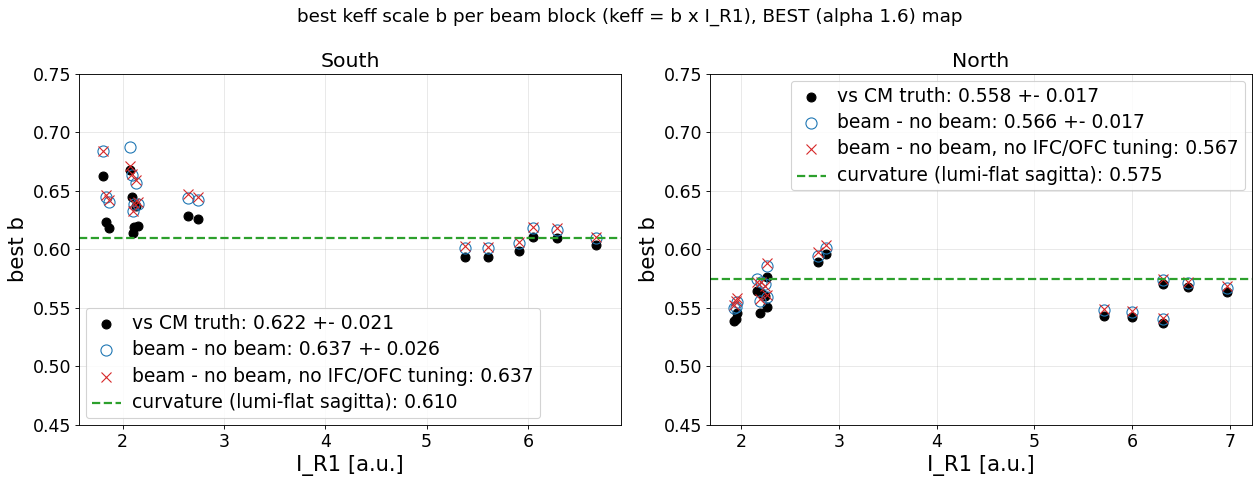

In [2]:
show(ta.fig_keff_slide())

**Result.** One $b$ per side for all luminosities ($\pm$3 %), the same for every reference and independent of the
static tuning: **keff ∝ GEM current, no offset**. At 79513: 1.29 / 1.30, below the CDB 1.59.

## 2. The CDB = linear space charge + a constant static curvature
Current CDB static, 79513 vs CM truth: sagitta vs keff for α 1.25 / 1.6 / 2.0. Open circles: keff where the sagitta is
flat in luminosity (17 blocks). Dashed: the CDB.

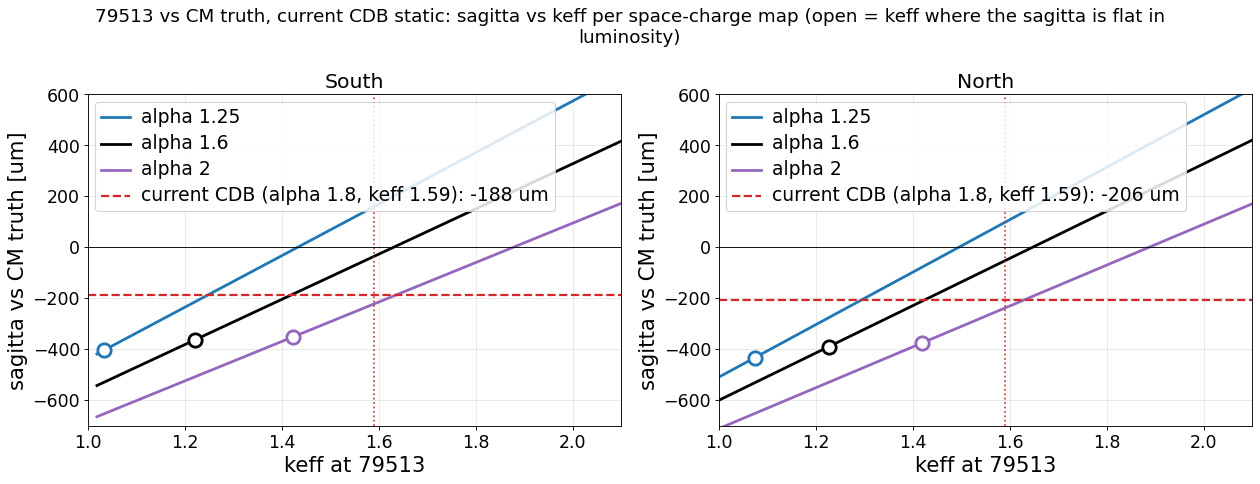

In [3]:
show(ta.fig_sag_tune())

**Result.** With keff linear in the GEM current every map stays below the CDB curvature, **by the same amount in every
block** (spread 11–23 µm over luminosity): a luminosity-independent, i.e. static, curvature. The CDB carries it in its
keff offset ($1.55 \times 0.185 \approx 0.3$, a constant Δkeff at every luminosity).

## 2b. Every model against the CM truth: $R\Delta\phi$, $d\phi$, $dR$
Models: current CDB; first tuned static (B$_r$ 0.8, IFC $-60$ / $-120$ V, frames 0) + α 1.6, $b$ 0.60; v4 (aligned static +
IFC / OFC) + α 1.6, $b$ 0.60; aligned static without voltages + α 1.6, $b$ 0.60. Mean of the blocks, low (795xx) and high
(80892 / 81558) luminosity. $dR$ only from clusters split over two pad rows with a balanced split (CM-cluster $dR$
saturates otherwise).

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/truthalign.py:1729: RuntimeWarning: Mean of empty slice
  ax.plot(PRC, np.nanmean(P, axis=0), '-o', ms=4, color=col, label=lab)


/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/truthalign.py:1756: RuntimeWarning: Mean of empty slice
  ax.plot(PRC, np.nanmean(P, axis=0), '-o', ms=4, color=col, label=lab)


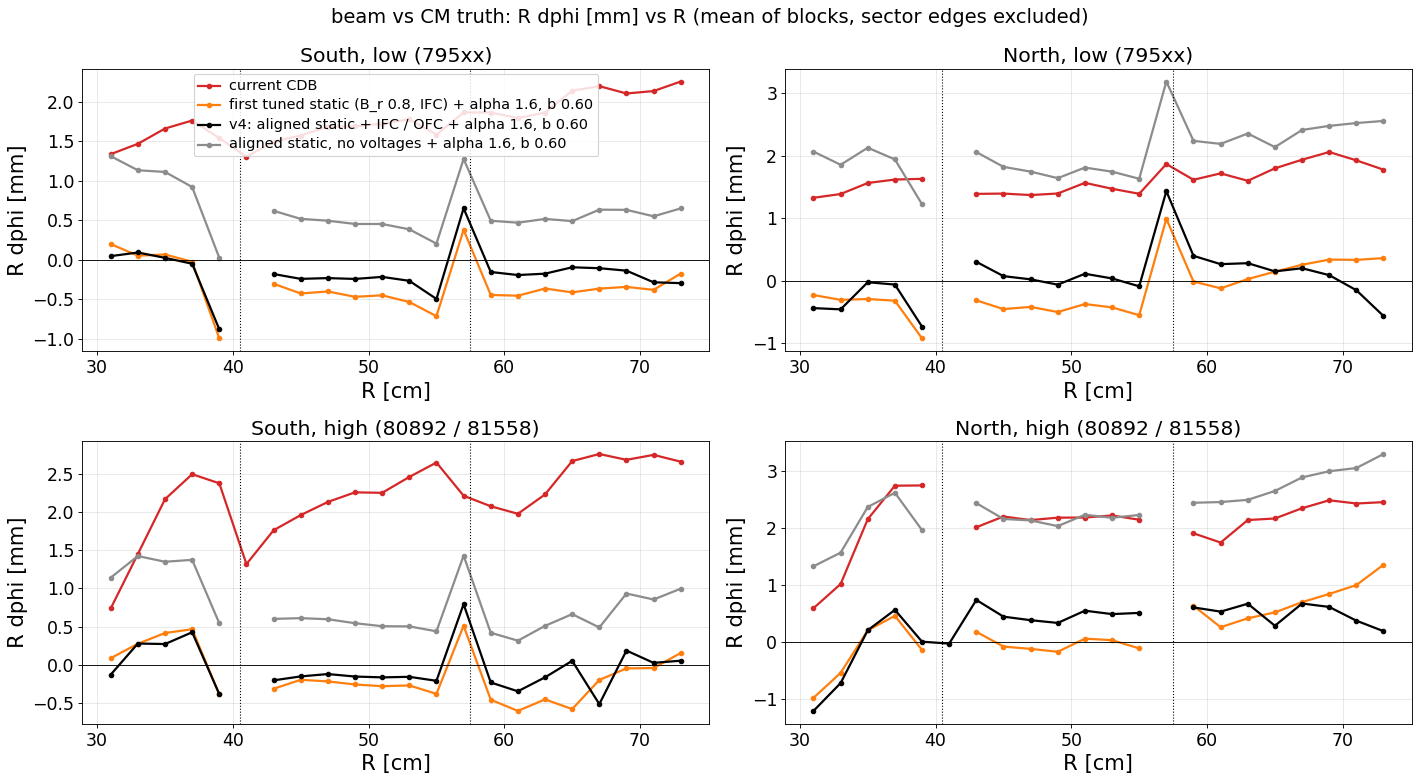

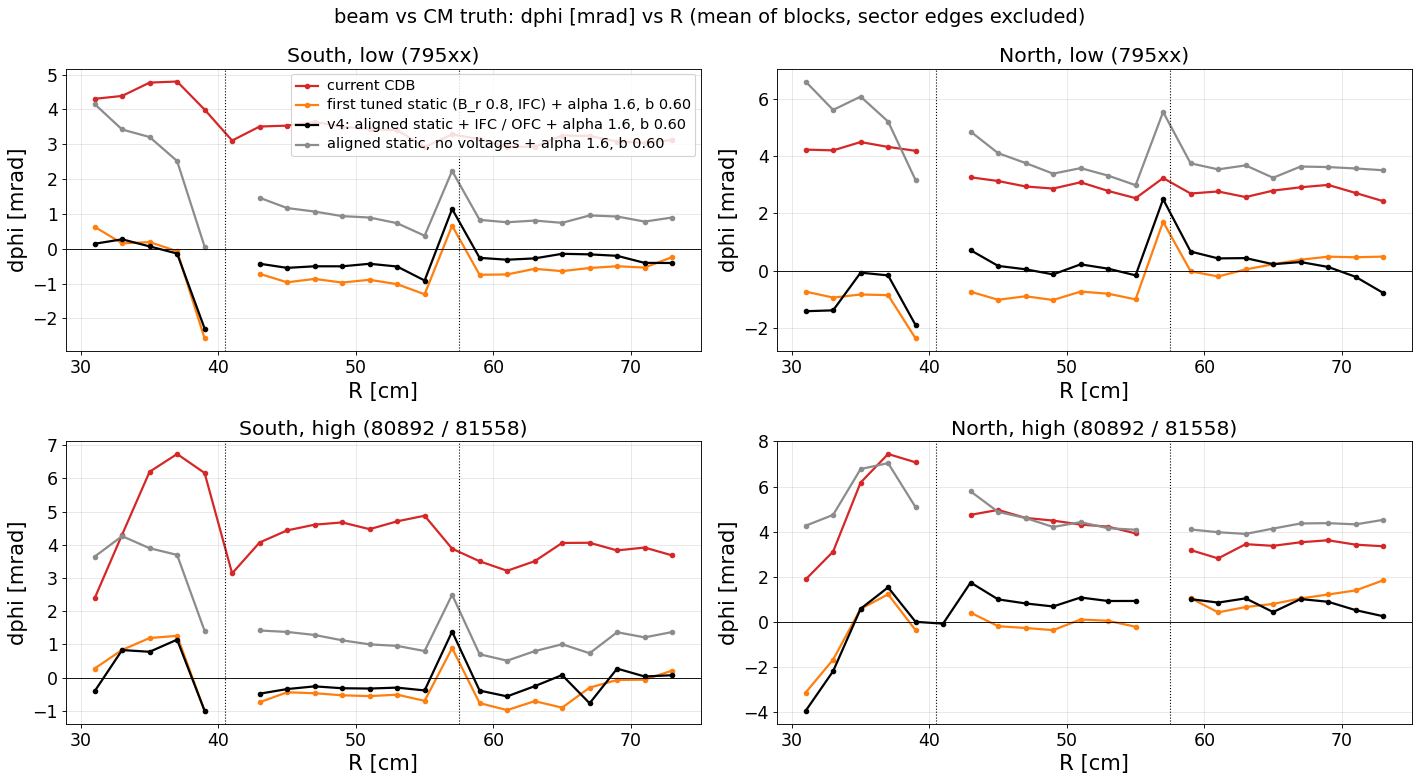

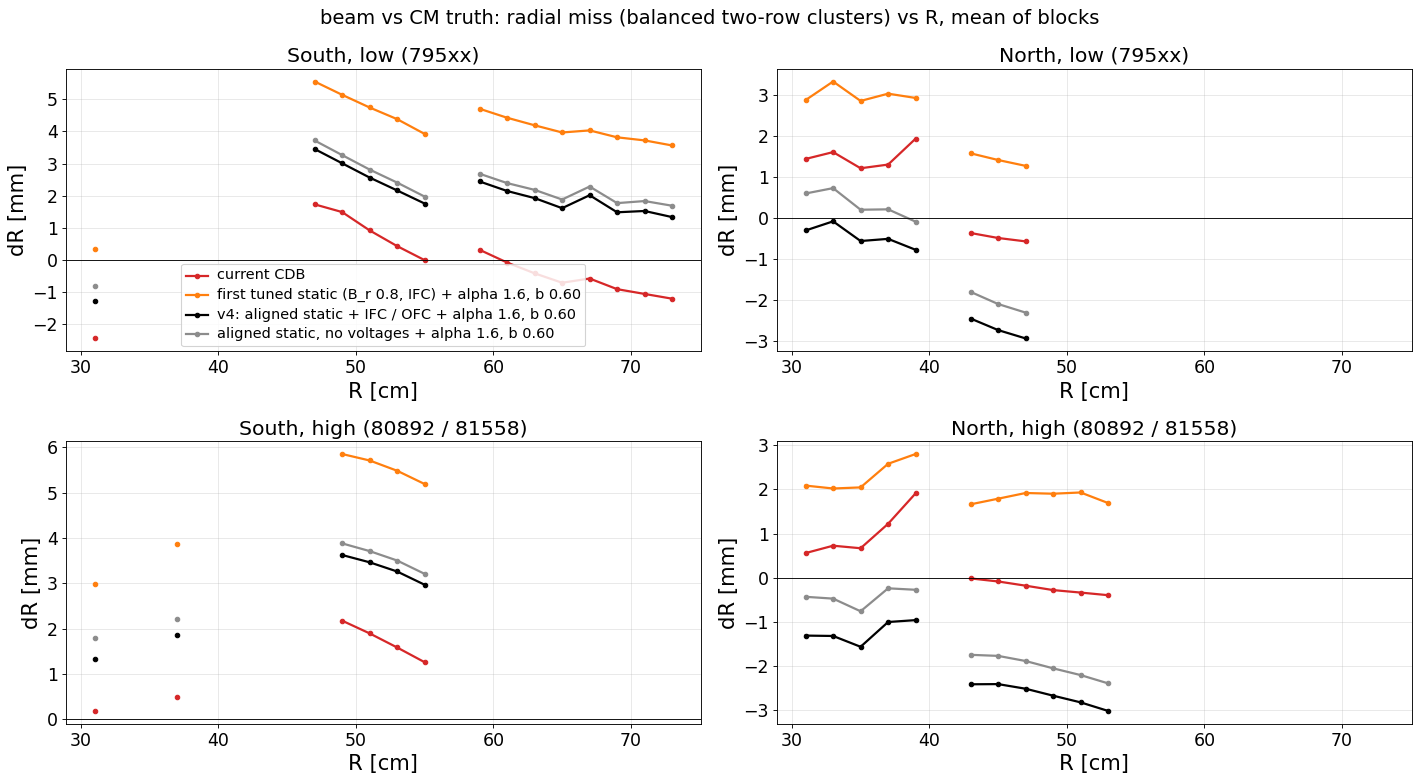

In [4]:
show(ta.fig_truth_profiles('rdphi'), ta.fig_truth_profiles('dphi'), ta.fig_truth_rmiss())

**Result.** Against the truth the CDB sits $+1.5$ to $+2$ mm high in $R\Delta\phi$, almost flat in $R$ (a flat offset, which a
TPC-only track absorbs); the tuned models bring the level to $\approx 0$ by changing the $R$ dependence (voltages, B$_r$).
The radial miss is smallest for the **CDB**; the tuned static models add $+2$ to $+4$ mm (South) -- another sign that
fitting the flat $R\Delta\phi$ offset away with field-cage / B$_r$ knobs is not what the drift does.

## 2c. Sagittas per block: vertex-constrained vs free R$^2$
Top: sagitta from the $d\phi$ slope (vertex constrained: a flat $R\Delta\phi$ offset counts as curvature). Bottom: the free
R$^2$ term of $R\Delta\phi(R)$ over 30–76 cm (what a TPC-only track keeps). Against the truth the free R$^2$ term is
fragile (it depends on the binning and the R1 structure by $\pm$100–300 µm); the paired differences below are not.

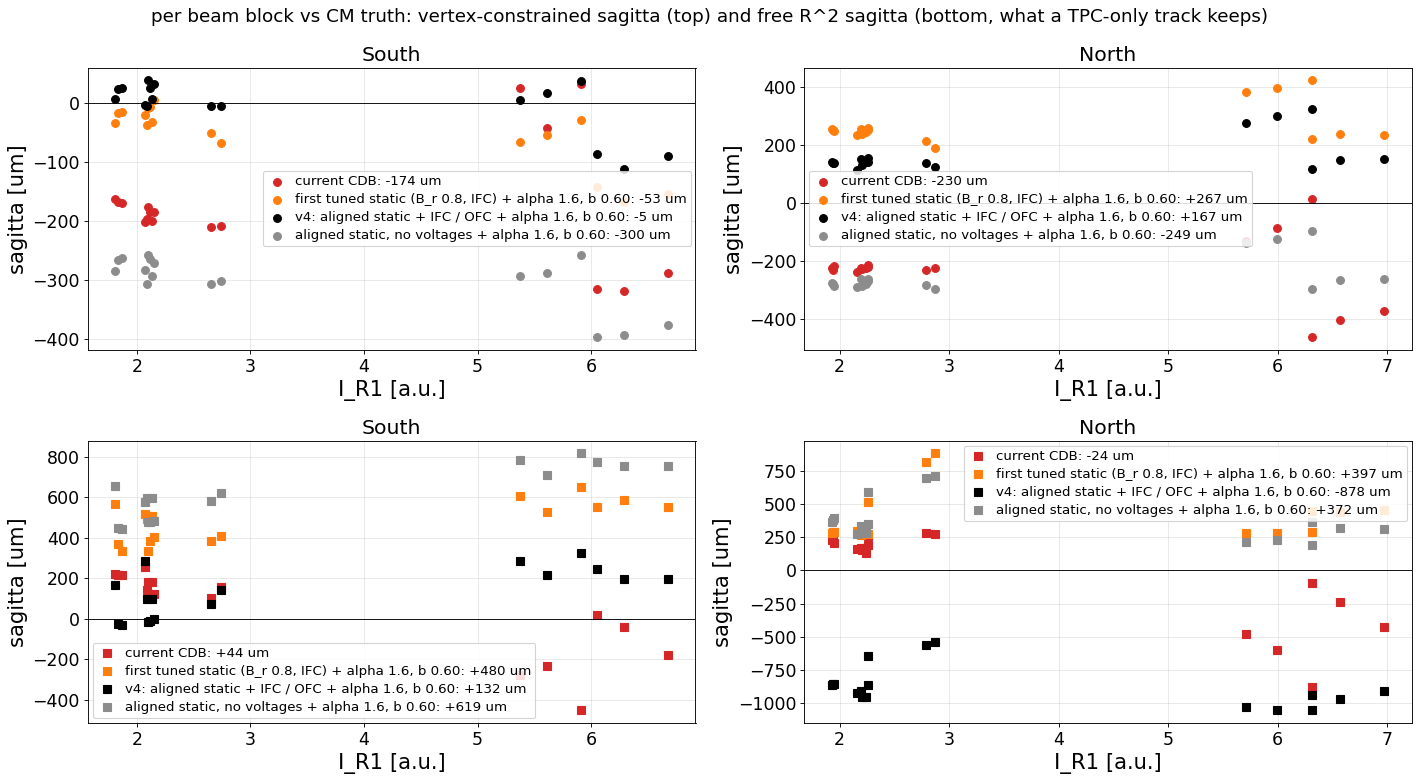

In [5]:
show(ta.fig_sagitta_blocks())

**Result.** Vertex-constrained (top): the CDB is the worst ($-174$ / $-230$ µm), the tuned models look better -- this is
what misled us. Free R$^2$ (bottom, low luminosity): the **CDB is closest to zero** ($+44$ / $-24$ µm); the first tuned
static $+480$ / $+397$ µm, v4 North $-878$ µm -- the same order as the K0s.

## 3. What a TPC-only track keeps: R$^2$ curvature, measured without the truth
The CDB and our corrections were applied to the **same laser clusters** (same job input, deterministic clustering), so
$\Delta(R\Delta\phi) = R\,(\phi_\mathrm{ours} - \phi_\mathrm{CDB})$ per 2 cm compares two corrections directly: no truth
matching, no alignment. Fit $\Delta(R) = a + b\,(R-52) + c\,(R-52)^2$:
- $a$ (offset) and $b$ (slope = rotation) are absorbed by a TPC-only track (they move its position and direction);
- $c$ is what changes its curvature: R$^2$ sagitta $= c\,L^2/4$ over $L$ = 46 cm (30–76 cm).

**What is plotted.** The static models we tried minus the CDB static (795xx beam blocks).

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/truthalign.py:1704: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0) if P else np.full(len(PRC), np.nan)


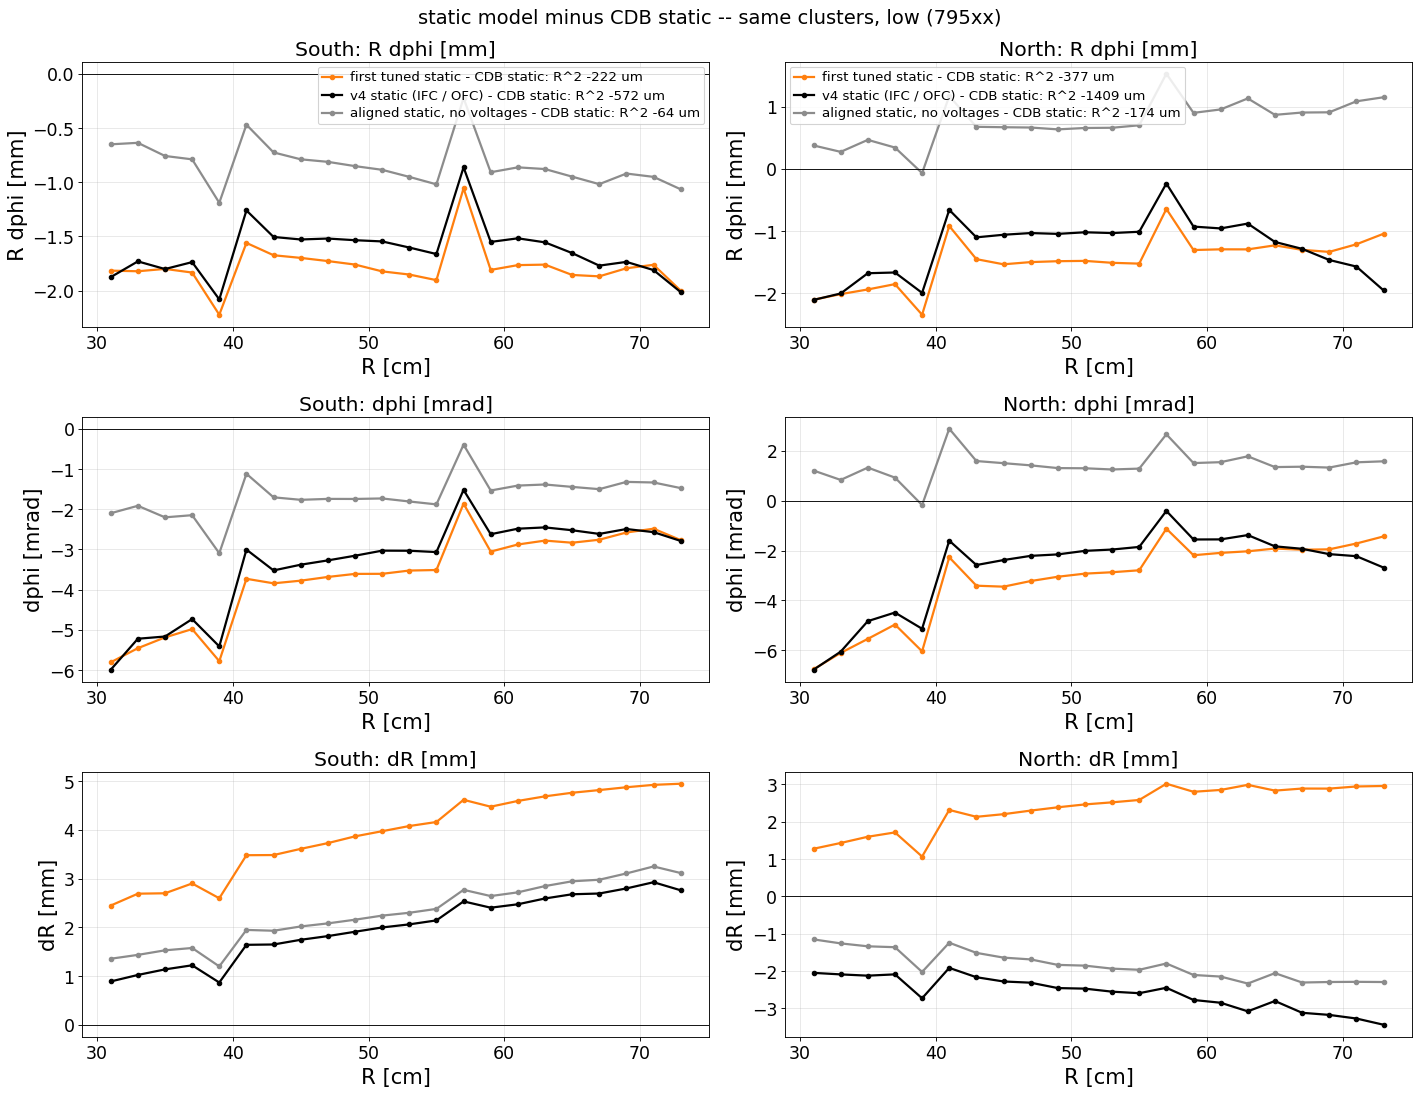

In [6]:
show(ta.fig_paired_q([('st_ns_bsG', 'cdb_st_bsC2', 'first tuned static - CDB static', 'tab:orange'),
                      ('st4', 'cdb_st_bsC2', 'v4 static (IFC / OFC) - CDB static', 'k'),
                      ('st4_nofc', 'cdb_st_bsC2', 'aligned static, no voltages - CDB static', '0.55')],
                     'static model minus CDB static'))

### 3b. Full corrections minus the CDB, low and high luminosity

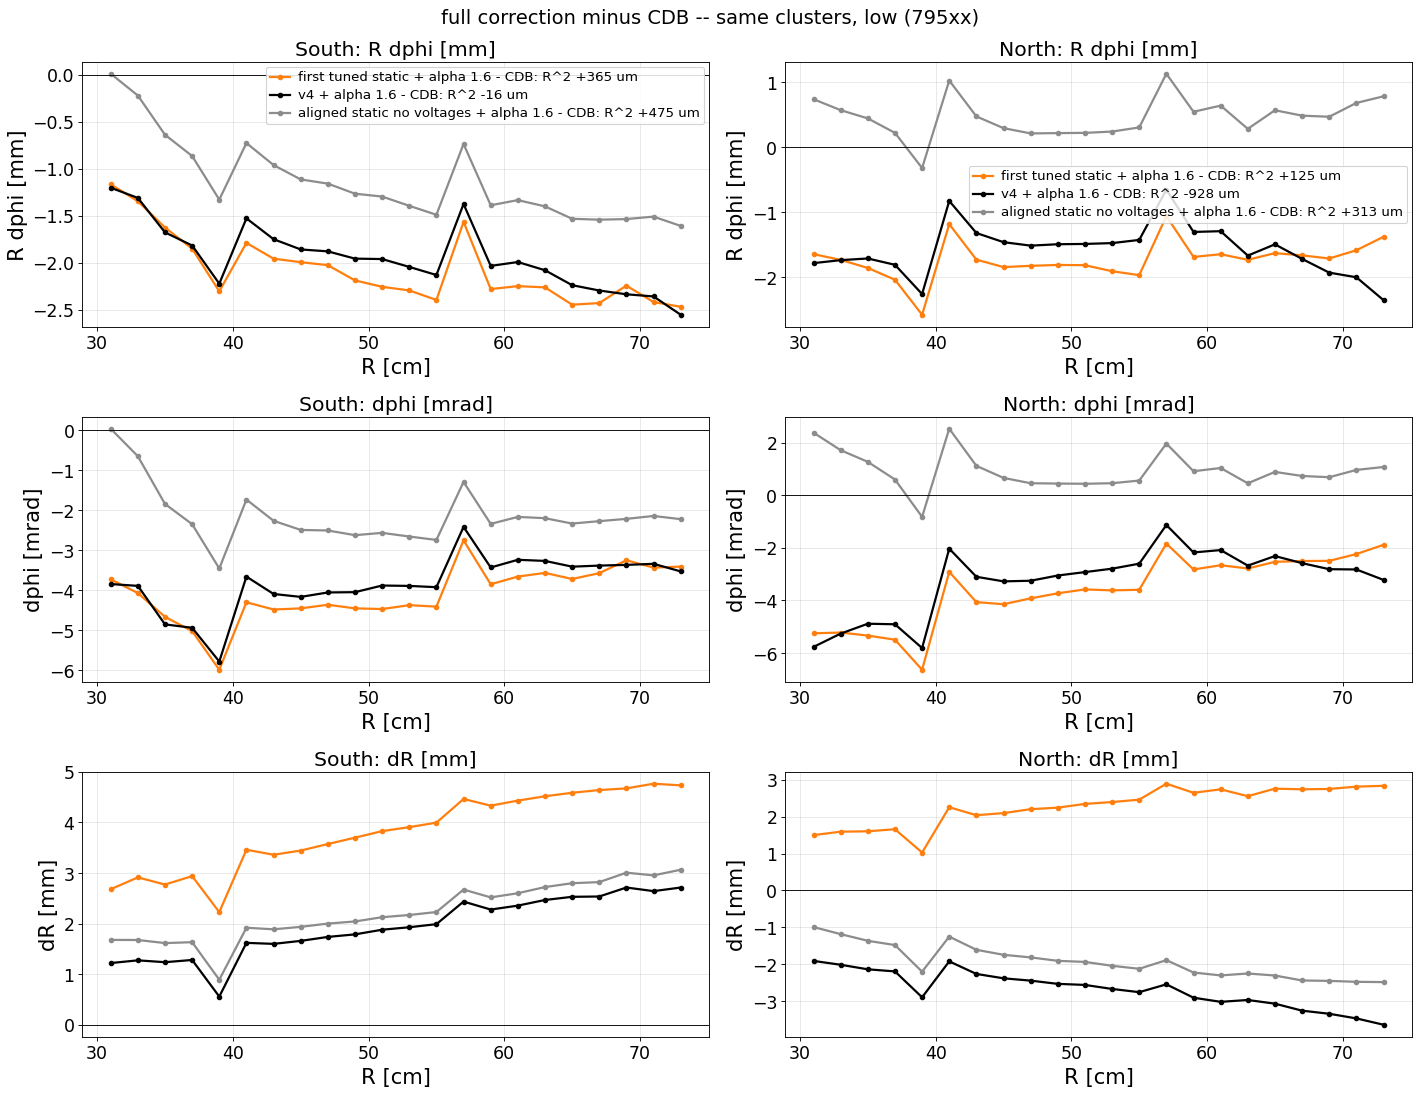

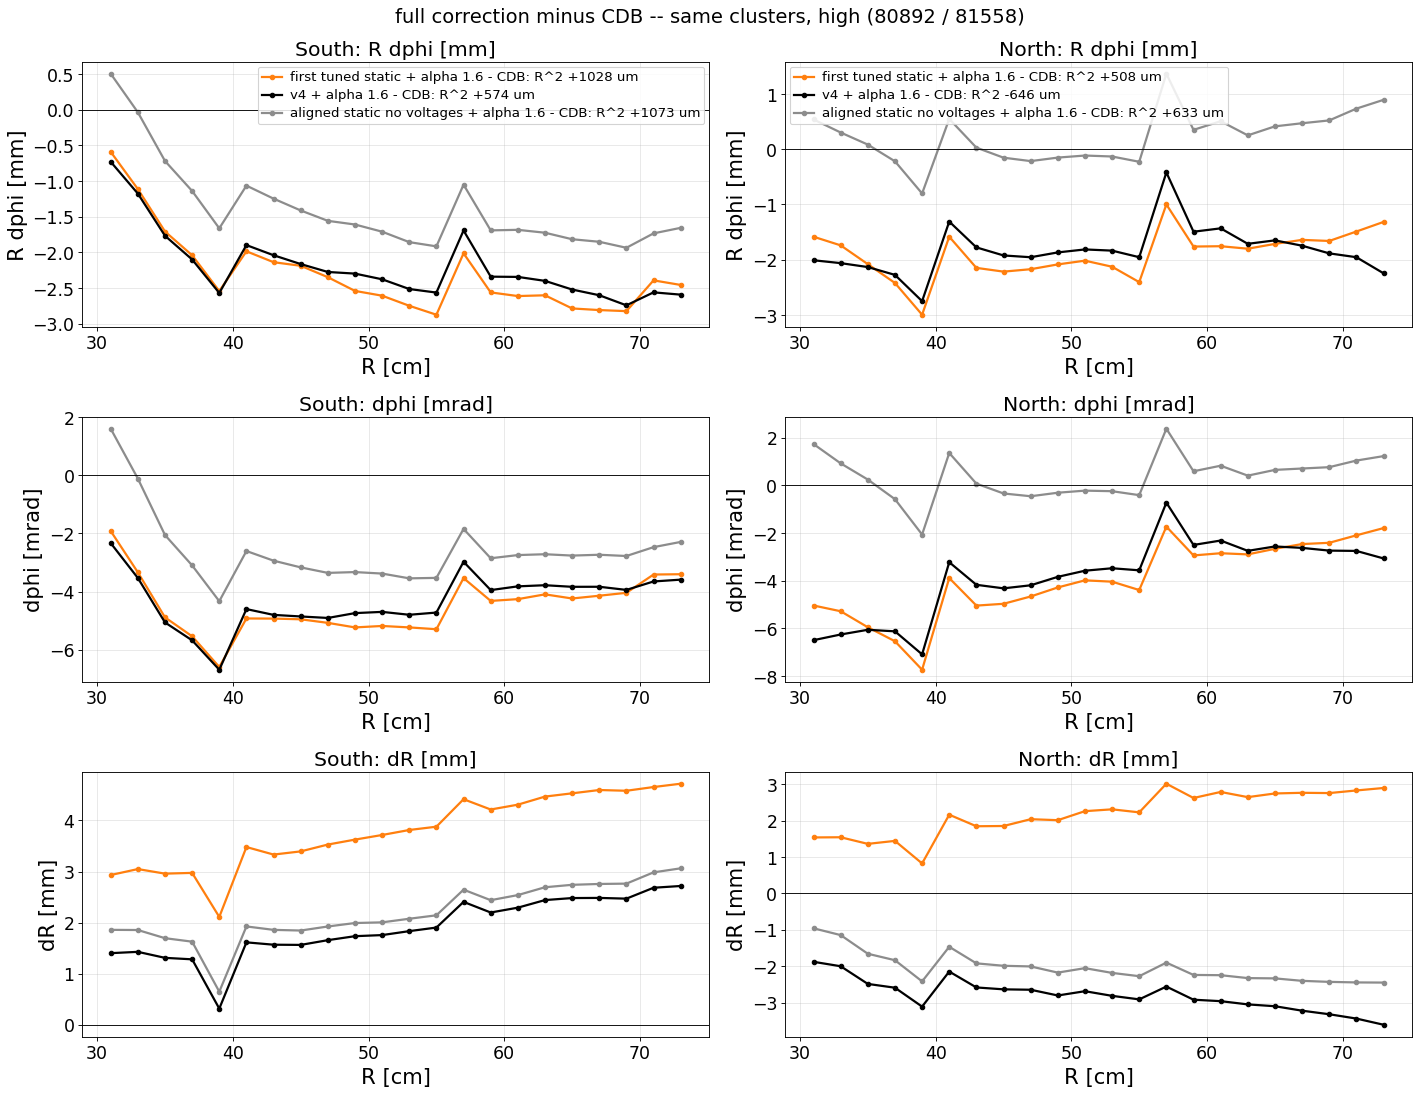

In [7]:
pairs = [('ns_a1p6_r22p75_w2_o0_b600', 'cdb', 'first tuned static + alpha 1.6 - CDB', 'tab:orange'),
         ('v4_a1p6_r22p75_w2_o0_b600', 'cdb', 'v4 + alpha 1.6 - CDB', 'k'),
         ('v4nofc_a1p6_r22p75_w2_o0_b600', 'cdb', 'aligned static no voltages + alpha 1.6 - CDB', '0.55')]
show(ta.fig_paired_q(pairs, 'full correction minus CDB'), ta.fig_paired_q(pairs, 'full correction minus CDB', 'high (80892 / 81558)'))

**Result.** The field-cage tuning of the v4 static model puts **−0.6 mm (South) / −1.4 mm (North)** of R$^2$ curvature
into the correction; the aligned static model without voltages differs from the CDB static by only −0.06 / −0.17 mm.

## 4. The K0s follow the R$^2$ curvature, not the vertex-constrained sagitta
Left: π⁻ / π⁺ in the K0s peak vs daughter $p_T$ (79513, TPC only, baseline cuts). Right: the largest imbalance vs the
R$^2$ curvature of each full correction minus the CDB (795xx, same clusters).

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/truthalign.py:1597: RuntimeWarning: Mean of empty slice
  return np.nanmean(P, axis=0) if P else None


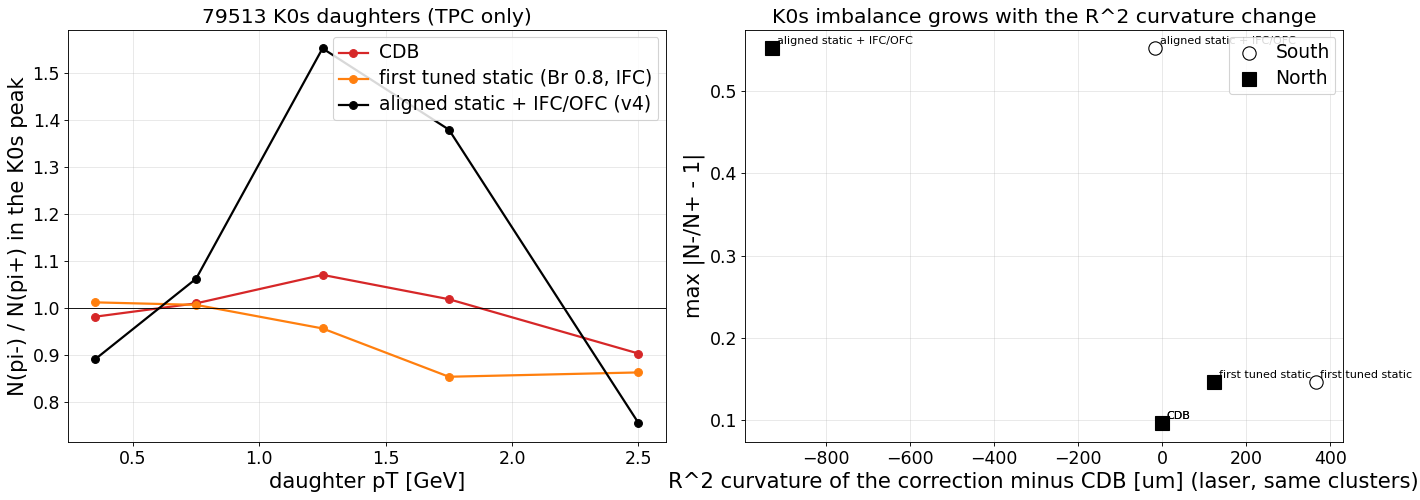

CDB                                  <pT-> / <pT+> 1.010   K0s mass rms 7.65 MeV   S/B 2.92
first tuned static (Br 0.8, IFC)     <pT-> / <pT+> 0.983   K0s mass rms 7.93 MeV   S/B 2.73
aligned static + IFC/OFC (v4)        <pT-> / <pT+> 1.081   K0s mass rms 8.99 MeV   S/B 2.51
first tuned static   minus CDB, South: offset -2.18 mm, slope -2.17 mrad, R^2 +365 um
first tuned static   minus CDB, North: offset -1.76 mm, slope +0.79 mrad, R^2 +125 um


v4                   minus CDB, South: offset -1.93 mm, slope -2.10 mrad, R^2 -16 um
v4                   minus CDB, North: offset -1.29 mm, slope -0.36 mrad, R^2 -928 um


In [8]:
show(ta.fig_k0s_vs_curv())
k = np.load(c.HERE + '/data/k0s_79513_summary.npz', allow_pickle=True)
for lab, mr, sg, sb in zip(k['labels'], k['mean_ratio'], k['sigma'], k['sb']):
    print(f"{lab:36s} <pT-> / <pT+> {mr:.3f}   K0s mass rms {sg:.2f} MeV   S/B {sb:.2f}")
for t, lab in (('ns_a1p6_r22p75_w2_o0_b600', 'first tuned static'), ('v4_a1p6_r22p75_w2_o0_b600', 'v4')):
    for s in (0, 1):
        print(f"{lab:20s} minus CDB, {c.SIDES[s]:5s}: offset {ta.dec3(ta.paired_mean(ta.LUMI['low (795xx)'], t, 'cdb', s))[0]:+.2f} mm, "
              f"slope {ta.dec3(ta.paired_mean(ta.LUMI['low (795xx)'], t, 'cdb', s))[1]:+.2f} mrad, R^2 {ta.dec3(ta.paired_mean(ta.LUMI['low (795xx)'], t, 'cdb', s))[2]:+.0f} um")

**Result.** CDB (reference) balanced; the first tuned static (+0.37 / +0.13 mm R$^2$) North off; v4 (−0.02 / −0.93 mm)
much worse ($N^-/N^+$ 1.55 at 1–1.5 GeV, σ 7.65 → 8.99 MeV). The vertex-constrained laser sagitta ranked them the other
way round: it turns a flat $R\Delta\phi$ offset into curvature, which a TPC-only track does not see. **The target for
TPC-only K0s is the CDB R$^2$ shape.**

## 5. Linear keff removes R$^2$ curvature relative to the CDB
Space-charge correction alone: α 1.6 with keff linear in the GEM current minus the CDB space charge (each with its own
static model subtracted, same clusters).

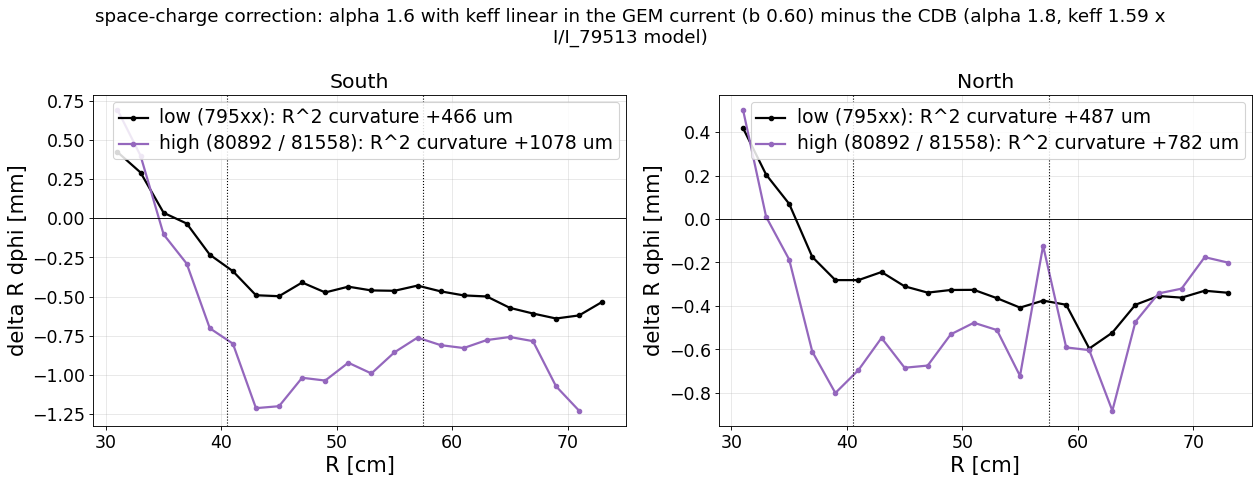

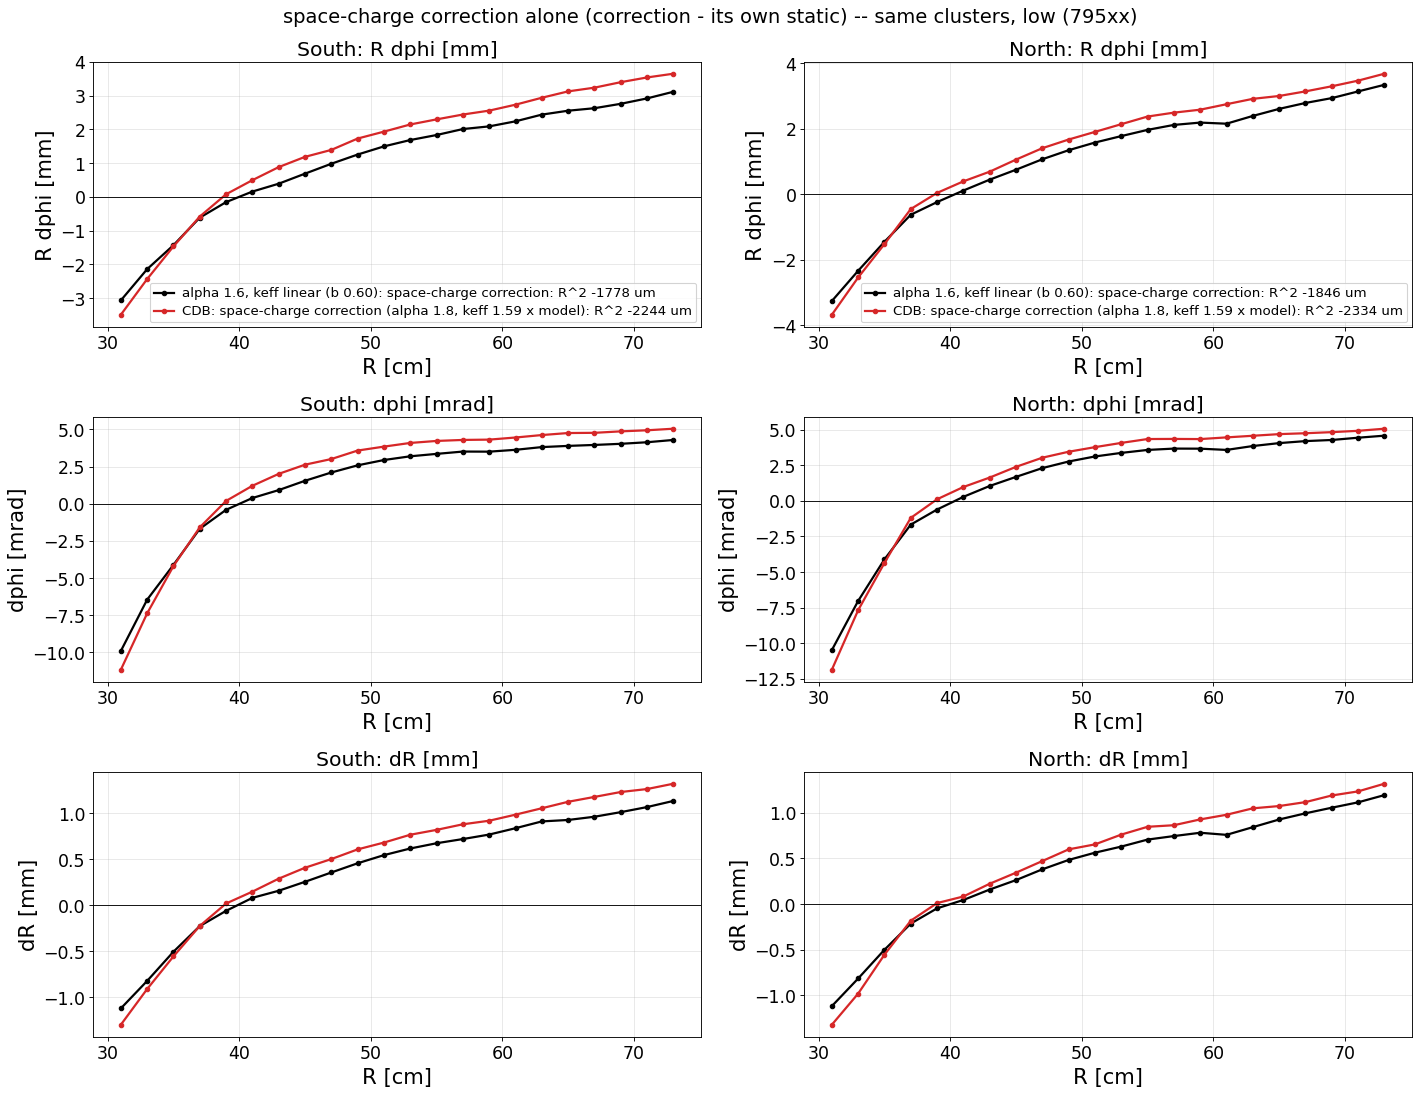

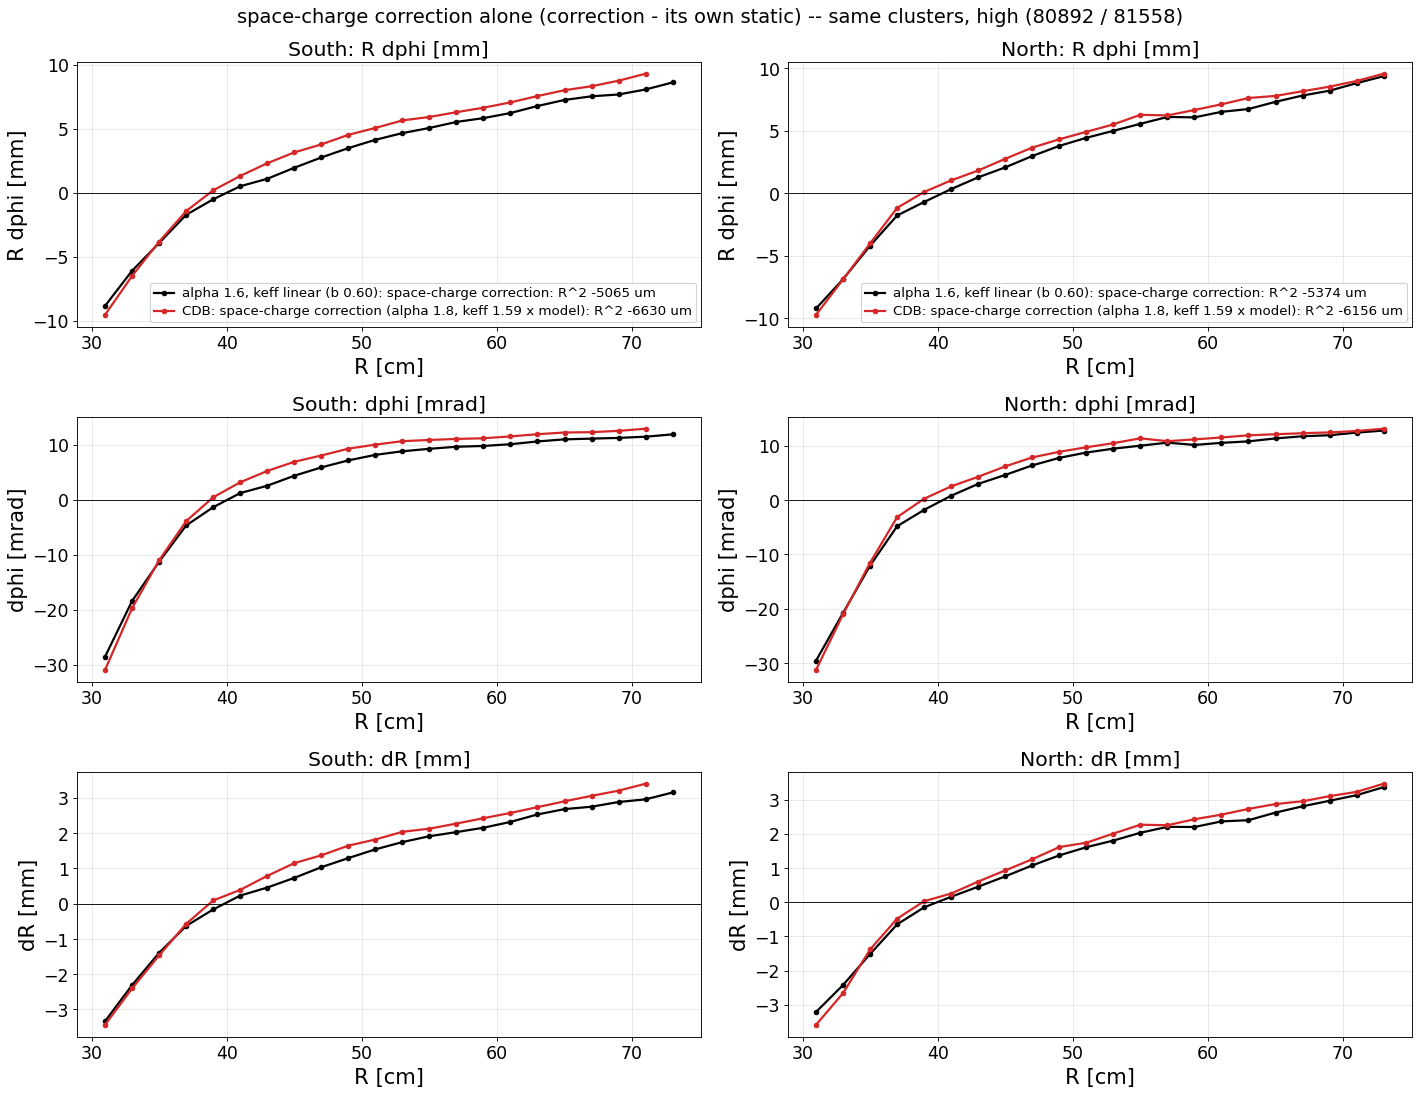

In [9]:
show(ta.fig_sc_part())
pairs = [('ns_a1p6_r22p75_w2_o0_b600', 'st_ns_bsG', 'alpha 1.6, keff linear (b 0.60): space-charge correction', 'k'),
         ('cdb', 'cdb_st_bsC2', 'CDB: space-charge correction (alpha 1.8, keff 1.59 x model)', 'tab:red')]
show(ta.fig_paired_q(pairs, 'space-charge correction alone (correction - its own static)'),
     ta.fig_paired_q(pairs, 'space-charge correction alone (correction - its own static)', 'high (80892 / 81558)'))

**Result.** +0.47 / +0.49 mm R$^2$ curvature at low luminosity (−135 µm per +0.1 keff, the rest from the map shape),
+1.1 / +0.8 mm at high luminosity. At 79513 this has to come back from the static model if the tracks are to keep the
CDB shape with physical keffs.

## 6. Case B: prediction against the CDB
B − CDB = (α 1.6 linear keff − CDB space charge) + (IFC / OFC response × case-B voltages); the IFC and OFC responses per
100 V are measured on the same no-beam clusters. The voltages solve R$^2$ curvature = 0 and slope = 0 vs the CDB at 795xx.

/home/yoren/.local/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/yoren/.local/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


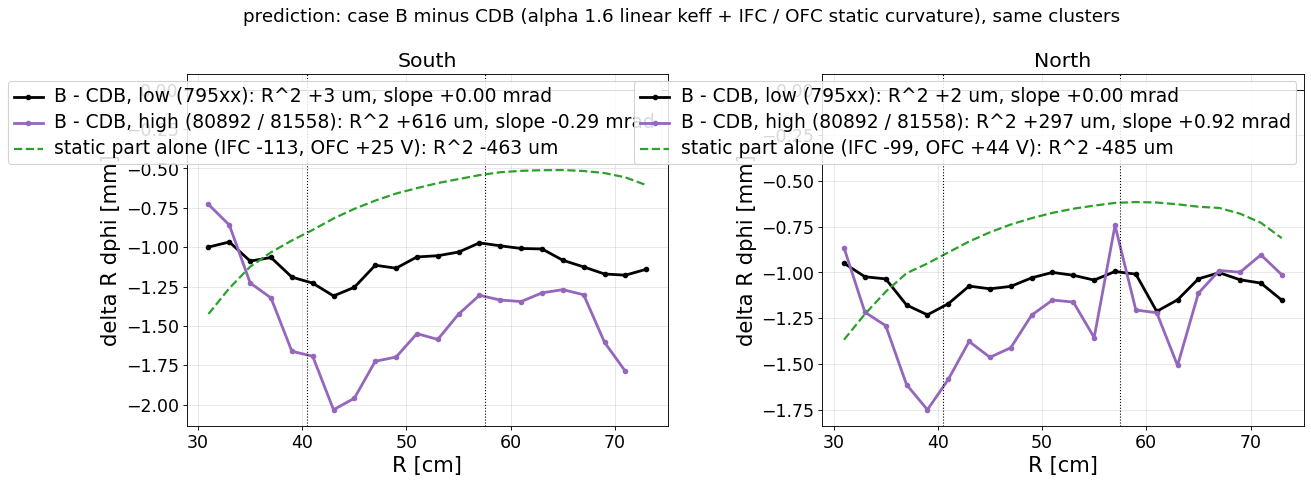

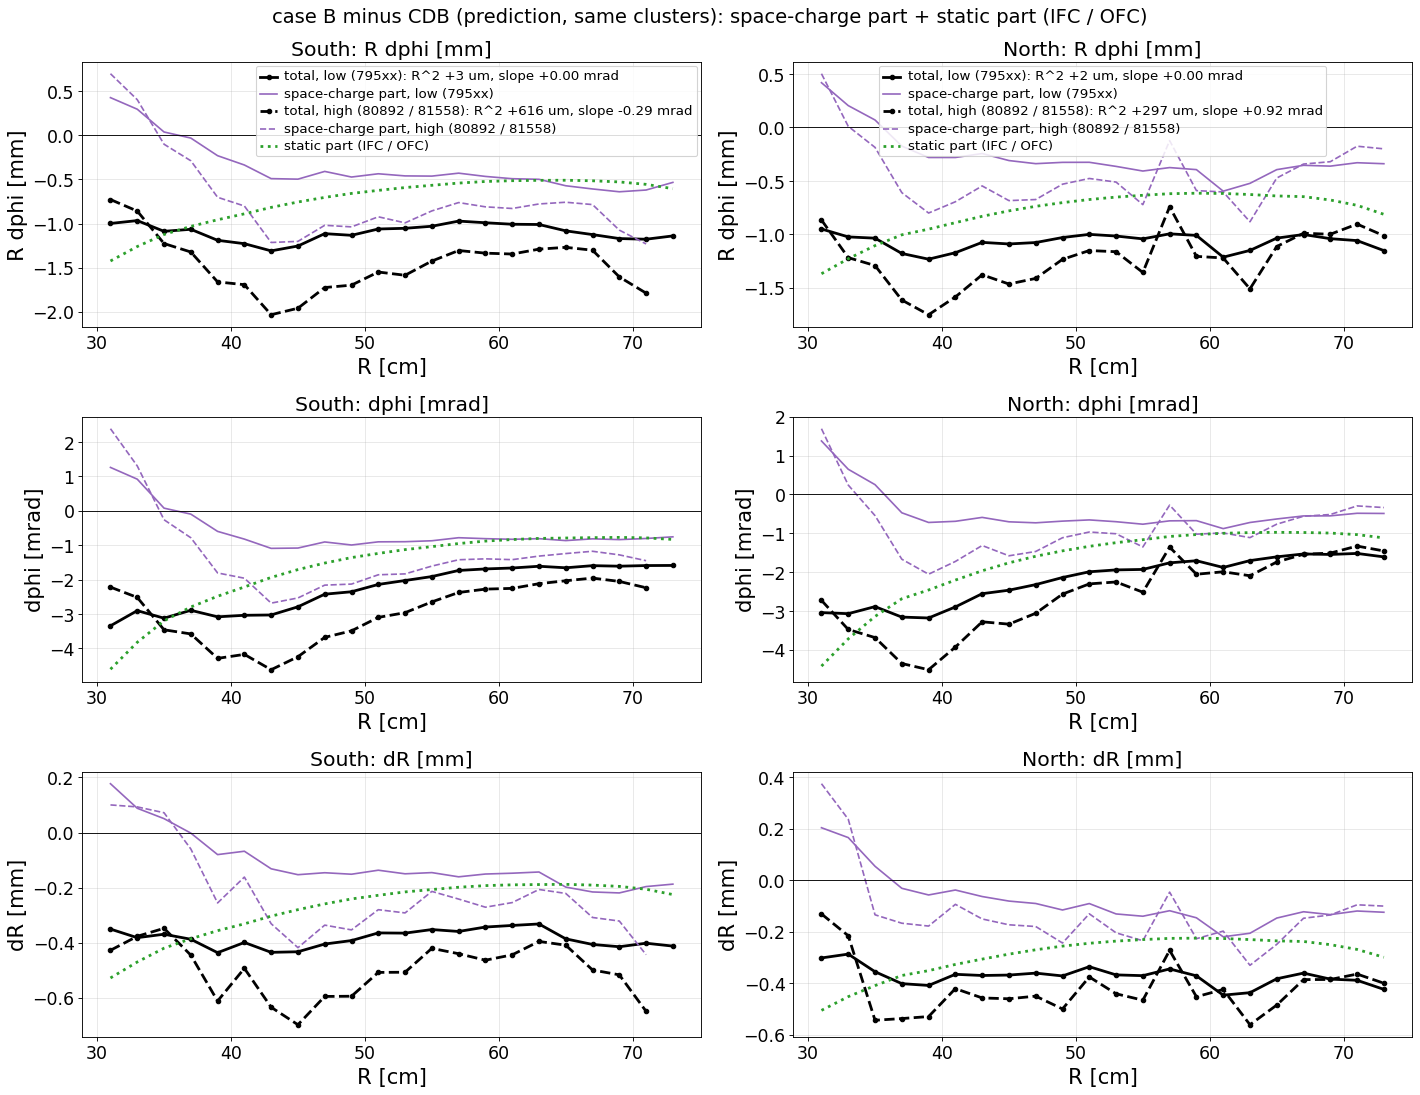

South: per +100 V  IFC offset/slope/R^2 = +0.40 mm / -1.95 mrad / +311 um;  OFC -0.57 / -1.63 / -449
   B - CDB, low (795xx)           : offset -1.10 mm, slope +0.00 mrad, R^2 curvature +3 um
   B - CDB, high (80892 / 81558)  : offset -1.64 mm, slope -0.29 mrad, R^2 curvature +616 um
North: per +100 V  IFC offset/slope/R^2 = +0.40 mm / -1.95 mrad / +309 um;  OFC -0.57 / -1.53 / -407
   B - CDB, low (795xx)           : offset -1.07 mm, slope +0.00 mrad, R^2 curvature +2 um


   B - CDB, high (80892 / 81558)  : offset -1.33 mm, slope +0.92 mrad, R^2 curvature +297 um


In [10]:
show(ta.fig_B_pred(), ta.fig_B_pred_q())
for s in (0, 1):
    tI, tO = ta.fc_response(s)
    print(f"{c.SIDES[s]}: per +100 V  IFC offset/slope/R^2 = {ta.dec3(tI)[0]:+.2f} mm / {ta.dec3(tI)[1]:+.2f} mrad / {ta.dec3(tI)[2]:+.0f} um;"
          f"  OFC {ta.dec3(tO)[0]:+.2f} / {ta.dec3(tO)[1]:+.2f} / {ta.dec3(tO)[2]:+.0f}")
    for gl, runs in ta.LUMI.items():
        o, sl, cv = ta.dec3(ta.predict_B(runs, s))
        print(f"   B - CDB, {gl:22s}: offset {o:+.2f} mm, slope {sl:+.2f} mrad, R^2 curvature {cv:+.0f} um")

**Result.**
- At 795xx (79513): case B has the **CDB R$^2$ curvature and slope** (0 by construction), with keff linear in the GEM
  current. Expected K0s: balanced like the CDB.
- A flat −1.1 mm $R\Delta\phi$ offset remains: it moves the TPC-only daughter tracks sideways together (V0 vertex, DCA),
  not the mass or the opening angle.
- At high luminosity B differs from the CDB (+0.6 / +0.3 mm R$^2$) because keff is linear there: that is the actual
  change to test next (80892 / 81558).

**Caveats.** The IFC / OFC are an effective curvature knob, with the PHGarfield $z$ dependence (ramp to the readout),
which the laser at full drift cannot check; the TPC-only K0s will. The 795xx prediction combines measured parts linearly.